# 02 · Modelado

**Objetivo:** entrenar un primer modelo KNN (baseline) para predecir el precio de alquiler por m²

In [67]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
import joblib
import os

- cargamos el dataset limpio

In [2]:
apartments = pd.read_csv("../data/clean/apartments_clean.csv")
apartments.shape

(9848, 40)

- elijo los features y el target

In [3]:
features = apartments.drop(columns=["price", "price_per_m2", "cityname", "state"])
target = apartments["price_per_m2"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.20, random_state=0)

In [5]:
X_train.head()

,bathrooms,bedrooms,has_photo,latitude,longitude,cats_allowed,dogs_allowed,AC,Alarm,Basketball,...,Pool,Refrigerator,Storage,TV,Tennis,View,Washer Dryer,Wood Floors,amenities_count,area_m2
7972,1.0,2.0,1,30.6378,-81.4612,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,111.483600
1176,1.0,0.0,1,29.7714,-95.4343,0,0,0,0,0,...,1,0,0,0,0,0,0,0,2,49.145687
7787,2.0,2.0,1,34.0394,-118.2656,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,108.417801
7552,2.0,2.0,1,32.8524,-97.0886,1,1,0,0,0,...,1,1,0,0,0,0,1,0,10,104.422972
1364,1.0,1.0,1,39.1471,-86.5136,1,1,0,0,0,...,0,1,0,0,0,0,0,0,6,51.096650


In [6]:
y_train.head()

7972    13.903390
1176    20.245927
7787    38.001140
7552    14.517878
1364    16.635141
Name: price_per_m2, dtype: float64

- Empezamos a entrenar el modelo con Knn

In [7]:
knn = KNeighborsRegressor()
knn

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None


In [8]:
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [9]:
pred = knn.predict(X_test)
pred

array([11.3866227 , 27.19414458, 16.36298277, ..., 11.61138988,
       11.62315116, 16.61000343], shape=(1970,))

In [10]:
y_test.values

array([12.17399668, 15.31787911, 15.6549956 , ...,  9.72040137,
       12.30708297, 12.24859299], shape=(1970,))

- Evaluación:

In [11]:
knn.score(X_test, y_test) 

0.6384315784477191

- Interpretación: R² = 0,63

El modelo explica el 63% de la variación del precio por m². Para un baseline sin escalar, sin ubicación por ciudad y sin ajustar nada, es un buen punto de partida

In [12]:
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 4.244693395101918
RMSE: 6.462656659515537


**Observación:** el modelo base explica el 63% de la variación del precio por m², con un error medio de 4,24 $/m². El RMSE, notablemente superior al MAE, indica la presencia de algunos errores grandes, asociados a viviendas de gama alta que se conservan por ser reales, pero que son escasas y difíciles de predecir. Este resultado servirá como referencia para medir las mejoras.

### Feature Engineering

Se aplicaran dos técnicas de escalado ('MinMaxScaler' y 'StandardScaler') y se comparan sus resultados para elegir la más adecuada.

- MinMaxScaler (Normalización):
    KNN es un algoritmo basado en distancias, por lo que las variables con valores grandes (como 'area_m2') dominan sobre las demás. Se aplica 'MinMaxScaler' para llevar todas las variables al rango 0-1.

In [13]:
normalizer = MinMaxScaler()
normalizer.fit(X_train)

X_train_norm = normalizer.transform(X_train)
X_test_norm = normalizer.transform(X_test)

X_train_norm = pd.DataFrame(X_train_norm, columns=X_train.columns)
X_test_norm = pd.DataFrame(X_test_norm, columns=X_test.columns)
X_train_norm.head()

,bathrooms,bedrooms,has_photo,latitude,longitude,cats_allowed,dogs_allowed,AC,Alarm,Basketball,...,Pool,Refrigerator,Storage,TV,Tennis,View,Washer Dryer,Wood Floors,amenities_count,area_m2
0,0.000000,0.250,1.0,0.231446,0.873225,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.088386
1,0.000000,0.000,1.0,0.209936,0.713853,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.111111,0.027930
2,0.133333,0.250,1.0,0.315898,0.453448,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.055556,0.085413
3,0.133333,0.250,1.0,0.286428,0.694985,1.0,1.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.555556,0.081539
4,0.000000,0.125,1.0,0.442708,0.815599,1.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.333333,0.029823


In [14]:
knn = KNeighborsRegressor()
knn.fit(X_train_norm, y_train)
pred_norm = knn.predict(X_test_norm)

r2 = knn.score(X_test_norm, y_test)
mae = mean_absolute_error(y_test, pred_norm)
rmse = np.sqrt(mean_squared_error(y_test, pred_norm))

print("R²:", r2)
print("MAE:", mae)
print("RMSE:", rmse)

R²: 0.4251811168786368
MAE: 5.166361004189854
RMSE: 8.14856905730407


- StandardScaler (Estandarizar):
    Como alternativa, se aplica StandardScaler', que transforma cada variable para que tenga media 0 y desviación típica 1. Es menos sensible a los valores extremos que 'MinMaxScaler'.

In [15]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)
X_train_scaled.head()

,bathrooms,bedrooms,has_photo,latitude,longitude,cats_allowed,dogs_allowed,AC,Alarm,Basketball,...,Pool,Refrigerator,Storage,TV,Tennis,View,Washer Dryer,Wood Floors,amenities_count,area_m2
0,-0.617355,0.267376,0.141201,-1.279784,0.831025,-1.161696,-1.077919,-0.261989,-0.047855,-0.185109,...,-0.696832,-0.675022,-0.428686,-0.148509,-0.227293,-0.124895,-0.343860,-0.195145,-0.911624,0.485254
1,-0.617355,-1.865673,0.141201,-1.436861,-0.053778,-1.161696,-1.077919,-0.261989,-0.047855,-0.185109,...,1.435067,-0.675022,-0.428686,-0.148509,-0.227293,-0.124895,-0.343860,-0.195145,-0.330692,-0.777835
2,1.005713,0.267376,0.141201,-0.663076,-1.499499,-1.161696,-1.077919,-0.261989,-0.047855,-0.185109,...,-0.696832,-0.675022,-0.428686,-0.148509,-0.227293,-0.124895,-0.343860,-0.195145,-0.621158,0.423135
3,1.005713,0.267376,0.141201,-0.878278,-0.158531,0.860810,0.927713,-0.261989,-0.047855,-0.185109,...,1.435067,1.481434,-0.428686,-0.148509,-0.227293,-0.124895,2.908158,-0.195145,1.993036,0.342192
4,-0.617355,-0.799149,0.141201,0.262947,0.511098,0.860810,0.927713,-0.261989,-0.047855,-0.185109,...,-0.696832,1.481434,-0.428686,-0.148509,-0.227293,-0.124895,-0.343860,-0.195145,0.831172,-0.738304


In [16]:
knn = KNeighborsRegressor()
knn.fit(X_train_scaled, y_train)
pred_scaled = knn.predict(X_test_scaled)

r2 = knn.score(X_test_scaled, y_test)
mae = mean_absolute_error(y_test, pred_scaled)
rmse = np.sqrt(mean_squared_error(y_test, pred_scaled))

print("R²:", r2)
print("MAE:", mae)
print("RMSE:", rmse)

R²: 0.4342781877693572
MAE: 5.196589192252274
RMSE: 8.083832368924284


**Observación:** ambos escalados empeoran el resultado respecto al baseline (R² de 0,63 a 0,43 con StandardScaler). Sin escalar, el modelo se apoyaba en 'area_m2' y las coordenadas, que probablemente son las variables más relevantes; al escalar, las 28 variables de servicios adquieren el mismo peso y podrían estar añadiendo ruido. Se elige 'StandardScaler' por obtener mejores métricas, y se aplicará selección de variables para comprobar esta hipótesis.

### 2. Selección de variables
Se analiza la correlación de cada variable con el target para identificar cuáles aportan información y cuáles podrían estar añadiendo ruido.

In [17]:
correlations = X_train.corrwith(y_train).abs().sort_values(ascending=False)
correlations

area_m2               0.321907
longitude             0.263869
bedrooms              0.261854
bathrooms             0.216628
Elevator              0.136533
Playground            0.099943
dogs_allowed          0.068225
Fireplace             0.067633
Garbage Disposal      0.061256
Tennis                0.058728
cats_allowed          0.054705
Patio/Deck            0.053172
Clubhouse             0.047375
Washer Dryer          0.047264
View                  0.045465
latitude              0.043933
Basketball            0.041913
Hot Tub               0.041631
amenities_count       0.037053
Wood Floors           0.035154
Doorman               0.033959
Dishwasher            0.032708
Pool                  0.019257
Gated                 0.018698
AC                    0.017736
Internet Access       0.017593
Storage               0.016221
Parking               0.016012
Gym                   0.012283
has_photo             0.011384
Cable or Satellite    0.011302
Luxury                0.011136
TV      

- El heatmap se limita a las variables principales, excluyendo a las columnas de los 27 servicios individuales, por legibilidad y porque su correlación con el target es muy baja (< 0,13), quedando representados por 'amenities_count'.

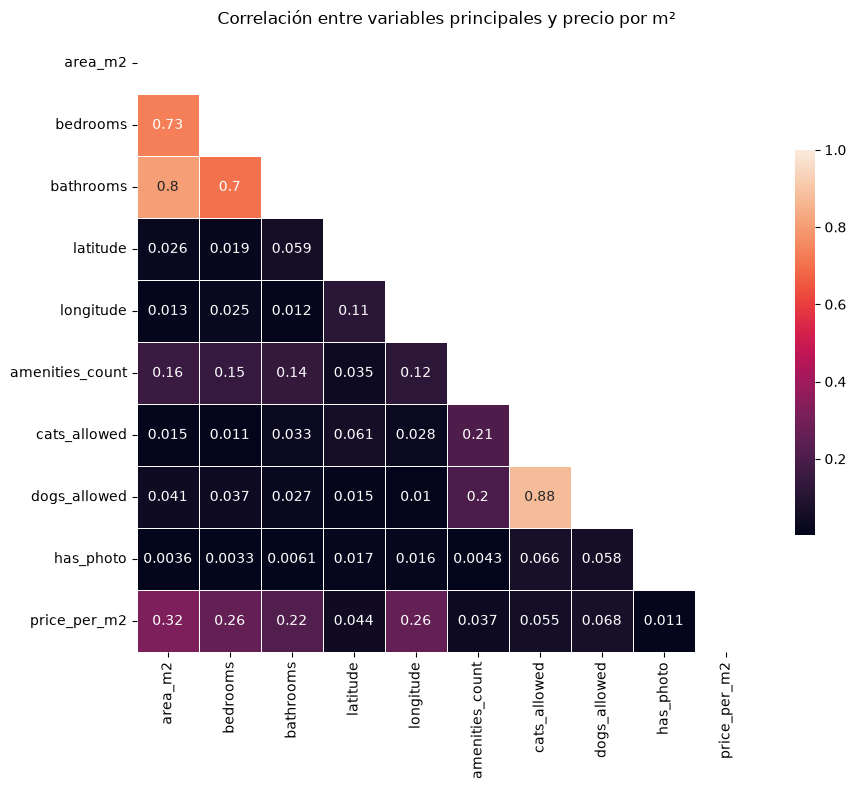

In [18]:
main_features = ["area_m2", "bedrooms", "bathrooms", "latitude", "longitude",
                 "amenities_count", "cats_allowed", "dogs_allowed", "has_photo"]

corr_data = X_train[main_features].copy()
corr_data["price_per_m2"] = y_train
corr = np.abs(corr_data.corr())

mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True

f, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(corr, mask=mask, vmax=1, square=True, linewidths=.5,
            cbar_kws={"shrink": .5}, annot=corr)
plt.title("Correlación entre variables principales y precio por m²")
plt.show()

se eliminan 'bathrooms' (muy correlacionada con 'area_m2') y 'cats_allowed' (muy correlacionada con 'dogs_allowed'), así como 'has_photo', 'amenities_count' y los servicios individuales por su baja correlación con el target. 'latitude' se conserva porque, junto con 'longitude', define la ubicación.

In [19]:
features_top = ["area_m2", "bedrooms", "latitude", "longitude", "dogs_allowed"]
X_train_top = X_train_scaled[features_top]
X_test_top = X_test_scaled[features_top]

knn = KNeighborsRegressor()
knn.fit(X_train_top, y_train)
pred_top = knn.predict(X_test_top)

In [20]:
r2 = knn.score(X_test_top, y_test)
mae = mean_absolute_error(y_test, pred_top)
rmse = np.sqrt(mean_squared_error(y_test, pred_top))

print("R²:", r2)
print("MAE:", mae)
print("RMSE:", rmse)

R²: 0.6223300988919049
MAE: 4.208251147874758
RMSE: 6.604987871383504


**Observación:** con 'StandardScaler' y 5 variables ('area_m2', 'bedrooms', 'latitude', 'longitude', 'dogs_allowed'), el KNN alcanza R² = 0,62 y MAE = 4,21, un rendimiento similar al baseline (R² = 0,63) pero con solo 5 variables en lugar de 36. Las diferencias entre configuraciones son pequeñas y dependen del split, por lo que se confirmarán con validación cruzada.

- EXPERIMENTOS  Y COMBINACIONES

Para comparar distintas combinaciones de escalado y variables sin repetir código, se define una función que entrena un KNN con parámetros por defecto y devuelve R², MAE y RMSE sobre el test.

In [21]:
def evaluate_knn(X_tr, X_te):
    """Entrena un KNN con parámetros por defecto y devuelve R², MAE y RMSE sobre el test."""
    knn = KNeighborsRegressor()
    knn.fit(X_tr, y_train)
    pred = knn.predict(X_te)

    r2 = knn.score(X_te, y_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    return round(r2, 3), round(mae, 2), round(float(rmse), 2)

features_bot: Son las 4 variables descartadas

In [22]:
features_bot = ["bathrooms", "cats_allowed", "has_photo", "amenities_count"]
X_train_bot = X_train_scaled[features_bot]
X_test_bot = X_test_scaled[features_bot]

print("A. Sin escalar, todas las variables (baseline):      ", evaluate_knn(X_train, X_test))
print("B. Sin escalar, solo las 5 variables principales:    ", evaluate_knn(X_train[features_top], X_test[features_top]))
print("C. Sin escalar, solo las 4 variables NO principales:    ", evaluate_knn(X_train[features_bot], X_test[features_bot]))
print("D. StandardScaler, todas las variables:              ", evaluate_knn(X_train_scaled, X_test_scaled))
print("E. StandardScaler, solo las 5 variables principales: ", evaluate_knn(X_train_top, X_test_top))
print("F. StandardScaler, solo las 4 variables NO principales: ", evaluate_knn(X_train_bot, X_test_bot))

A. Sin escalar, todas las variables (baseline):       (0.638, 4.24, 6.46)
B. Sin escalar, solo las 5 variables principales:     (0.619, 4.26, 6.64)
C. Sin escalar, solo las 4 variables NO principales:     (-0.042, 7.27, 10.97)
D. StandardScaler, todas las variables:               (0.434, 5.2, 8.08)
E. StandardScaler, solo las 5 variables principales:  (0.622, 4.21, 6.6)
F. StandardScaler, solo las 4 variables NO principales:  (-0.056, 7.52, 11.04)


**Observación:** el baseline (A, R² = 0,638) y las configuraciones con 5 variables (B y E, R² ≈ 0,62) obtienen resultados muy similares, por lo que con solo 5 variables se mantiene el rendimiento; escalar todas las variables empeora claramente (D, 0,43), y las 4 variables descartadas no aportan información (C y F, R² negativo).

Para comparar KNN con otros algoritmos (regresión lineal y árbol de decisión), se define una función general que acepta cualquier modelo de regresión y devuelve las mismas métricas.

In [23]:
def evaluate_model(model, X_tr, X_te):
    """Entrena el modelo recibido y devuelve R², MAE y RMSE sobre el test."""
    model.fit(X_tr, y_train)
    pred = model.predict(X_te)

    r2 = model.score(X_te, y_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    return round(r2, 3), round(mae, 2), round(float(rmse), 2)

In [24]:
print("Regresión lineal, todas las variables:         ", evaluate_model(LinearRegression(), X_train, X_test))
print("Regresión lineal, 5 variables principales:     ", evaluate_model(LinearRegression(), X_train[features_top], X_test[features_top]))
print("Regresión lineal, 4 variables NO principales:  ", evaluate_model(LinearRegression(), X_train[features_bot], X_test[features_bot]))

print("Árbol de decisión, todas las variables:        ", evaluate_model(DecisionTreeRegressor(random_state=0), X_train, X_test))
print("Árbol de decisión, 5 variables principales:    ", evaluate_model(DecisionTreeRegressor(random_state=0), X_train[features_top], X_test[features_top]))
print("Árbol de decisión, 4 variables NO principales: ", evaluate_model(DecisionTreeRegressor(random_state=0), X_train[features_bot], X_test[features_bot]))

Regresión lineal, todas las variables:          (0.227, 6.34, 9.45)
Regresión lineal, 5 variables principales:      (0.178, 6.62, 9.74)
Regresión lineal, 4 variables NO principales:   (0.054, 7.14, 10.46)
Árbol de decisión, todas las variables:         (0.665, 3.9, 6.22)
Árbol de decisión, 5 variables principales:     (0.614, 4.04, 6.67)
Árbol de decisión, 4 variables NO principales:  (0.044, 7.15, 10.51)


**Observación:** el árbol de decisión con todas las variables es el mejor modelo (R² = 0,665, MAE = 3,90 $/m²), seguido de su versión con 5 variables (0,61) y muy por encima de la regresión lineal (0,23), que no capta relaciones no lineales como la ubicación. En ambos modelos, las 4 variables descartadas no aportan información (R² ≈ 0,05).

- Codificación de la ubicación (One-Hot Encoding)
La variable 'state' se transforma con 'get_dummies' en una columna binaria por estado, para incorporar la ubicación a nivel de mercado regional.

In [25]:
state_dummies = pd.get_dummies(apartments["state"], prefix="state", dtype=int)

X_train_state = pd.concat([X_train[features_top], state_dummies.loc[X_train.index]], axis=1)
X_test_state = pd.concat([X_test[features_top], state_dummies.loc[X_test.index]], axis=1)
X_train_state.shape

(7878, 56)

In [26]:
print("Regresión lineal, todas las variables + estados:      ", evaluate_model(LinearRegression(), pd.concat([X_train, state_dummies.loc[X_train.index]], axis=1), pd.concat([X_test, state_dummies.loc[X_test.index]], axis=1)))
print("Regresión lineal, 5 variables principales + estados:  ", evaluate_model(LinearRegression(), X_train_state, X_test_state))

print("Árbol de decisión, todas las variables + estados:     ", evaluate_model(DecisionTreeRegressor(random_state=0), pd.concat([X_train, state_dummies.loc[X_train.index]], axis=1), pd.concat([X_test, state_dummies.loc[X_test.index]], axis=1)))
print("Árbol de decisión, 5 variables principales + estados: ", evaluate_model(DecisionTreeRegressor(random_state=0), X_train_state, X_test_state))

Regresión lineal, todas las variables + estados:       (0.544, 4.75, 7.26)
Regresión lineal, 5 variables principales + estados:   (0.514, 4.92, 7.49)
Árbol de decisión, todas las variables + estados:      (0.668, 3.93, 6.19)
Árbol de decisión, 5 variables principales + estados:  (0.653, 3.94, 6.33)


**Observación:** los estados mejoran mucho la regresión lineal (hasta R² = 0,54 con todas las variables), pero apenas aportan al árbol (0,668 frente a 0,665 sin estados), que ya capta la ubicación con las coordenadas. El mejor modelo sigue siendo el árbol de decisión (R² ≈ 0,67), y la configuración final se decidirá con validación cruzada.

### Interpretación de los modelos
**Coeficientes de la regresión lineal:** indican cuánto cambia el precio por m² cuando una variable aumenta en una unidad, manteniendo las demás constantes.

In [27]:
lin_reg = LinearRegression()
print("Regresión lineal, 5 principales + estados:", evaluate_model(lin_reg, X_train_state, X_test_state))

Regresión lineal, 5 principales + estados: (0.514, 4.92, 7.49)


In [28]:
lin_reg_coef = {feature : coef for feature, coef in zip(X_train_state.columns, lin_reg.coef_)}
lin_reg_coef

{'area_m2': np.float64(-0.0652813209841579),
 'bedrooms': np.float64(-0.023457244918884096),
 'latitude': np.float64(0.6987768525831967),
 'longitude': np.float64(-0.5651207892991326),
 'dogs_allowed': np.float64(0.009323815074181674),
 'state_AK': np.float64(-48.36872017325295),
 'state_AL': np.float64(6.7522805360039815),
 'state_AR': np.float64(-3.1725158426322704),
 'state_AZ': np.float64(-7.618384076618613),
 'state_CA': np.float64(5.804581256042731),
 'state_CO': np.float64(-4.379091329516344),
 'state_CT': np.float64(9.688702214512613),
 'state_DC': np.float64(27.240766767033552),
 'state_DE': np.float64(7.175214513263701),
 'state_FL': np.float64(15.627396448189796),
 'state_GA': np.float64(6.412355016532231),
 'state_HI': np.float64(-4.756744322272372),
 'state_IA': np.float64(-7.409389073191852),
 'state_ID': np.float64(-17.151549436980265),
 'state_IL': np.float64(4.343444723304174),
 'state_IN': np.float64(0.07503777108675891),
 'state_KS': np.float64(-6.1091362076717655),


**Importancia de variables del árbol de decisión:** indica qué proporción de la capacidad predictiva del árbol aporta cada variable. La suma de todas las importancias es 1.

In [29]:
tree = DecisionTreeRegressor(random_state=0)
print("Árbol de decisión, 5 principales + estados:", evaluate_model(tree, X_train_state, X_test_state))

Árbol de decisión, 5 principales + estados: (0.653, 3.94, 6.33)


In [30]:
tree_importance = {feature : importance for feature, importance in zip(X_train_state.columns, tree.feature_importances_)}
tree_importance

{'area_m2': np.float64(0.28308539856932186),
 'bedrooms': np.float64(0.02258191884728577),
 'latitude': np.float64(0.11080611198395851),
 'longitude': np.float64(0.270301551452195),
 'dogs_allowed': np.float64(0.013659178093858372),
 'state_AK': np.float64(0.00047311432547356814),
 'state_AL': np.float64(0.00552662232879056),
 'state_AR': np.float64(4.516692786136238e-05),
 'state_AZ': np.float64(3.3954347472949414e-05),
 'state_CA': np.float64(0.2480322387599765),
 'state_CO': np.float64(0.0023300230524511897),
 'state_CT': np.float64(0.00030716060370741816),
 'state_DC': np.float64(0.005403450798535247),
 'state_DE': np.float64(0.0),
 'state_FL': np.float64(6.265102938297996e-05),
 'state_GA': np.float64(0.00029988065099609203),
 'state_HI': np.float64(8.033438329549156e-07),
 'state_IA': np.float64(0.00043459541575316575),
 'state_ID': np.float64(9.905214274924129e-05),
 'state_IL': np.float64(0.0032124218333784587),
 'state_IN': np.float64(0.0007152738177930372),
 'state_KS': np.fl

In [31]:
tree_importance_sorted = dict(sorted(tree_importance.items(), key=lambda item: item[1], reverse=True))
tree_importance_sorted

{'area_m2': np.float64(0.28308539856932186),
 'longitude': np.float64(0.270301551452195),
 'state_CA': np.float64(0.2480322387599765),
 'latitude': np.float64(0.11080611198395851),
 'bedrooms': np.float64(0.02258191884728577),
 'state_WA': np.float64(0.015473949235406887),
 'dogs_allowed': np.float64(0.013659178093858372),
 'state_MA': np.float64(0.0071974687278422355),
 'state_AL': np.float64(0.00552662232879056),
 'state_DC': np.float64(0.005403450798535247),
 'state_IL': np.float64(0.0032124218333784587),
 'state_CO': np.float64(0.0023300230524511897),
 'state_TN': np.float64(0.0017693632928172686),
 'state_NY': np.float64(0.001221409931712019),
 'state_IN': np.float64(0.0007152738177930372),
 'state_OR': np.float64(0.0006405532163844701),
 'state_PA': np.float64(0.0006180995325744371),
 'state_VA': np.float64(0.0005844406340500876),
 'state_MI': np.float64(0.0005662459666192801),
 'state_AK': np.float64(0.00047311432547356814),
 'state_IA': np.float64(0.00043459541575316575),
 'sta

Si casi todos los estados aportan cero, quizá podríamos sustituir las 51 columnas por una sola: state_CA (“¿está en California?”). El modelo pasaría de 56 variables a 6, sería mucho más simple y tendríamos un hallazgo muy fuerte para la presentación.

Pero, como siempre, hay que comprobarlo con datos antes de decidir:

In [32]:
print("Árbol, 5 principales + todos los estados: ", evaluate_model(DecisionTreeRegressor(random_state=0), X_train_state, X_test_state))
print("Árbol, 5 principales + solo California:   ", evaluate_model(DecisionTreeRegressor(random_state=0), X_train_state[features_top + ["state_CA"]], X_test_state[features_top + ["state_CA"]]))

Árbol, 5 principales + todos los estados:  (0.653, 3.94, 6.33)
Árbol, 5 principales + solo California:    (0.634, 3.99, 6.5)


**Observación:** sustituir los 51 estados por una única variable 'state_CA' apenas reduce el rendimiento (R² de 0,653 a 0,634), lo que confirma que California concentra casi todo el efecto geográfico de los estados.
- Se toma la decision de mantener todos los estados.

## Decisión: configuración de variables para el modelo a probar

Se elige el **árbol de decisión con las 5 variables principales + estados** (`area_m2`, `bedrooms`, `latitude`, `longitude`, `dogs_allowed` y los estados codificados con One-Hot Encoding) como configuración de referencia para el resto del proyecto.

**Justificación:**
- Su rendimiento (R² = 0,653) es prácticamente igual al del árbol con todas las variables + estados (R² = 0,668). La diferencia de 0,015 es menor que la variabilidad observada entre distintas particiones train/test, por lo que no es significativa.
- Es un modelo mucho más simple: usa 56 variables en lugar de 87, lo que lo hace más fácil de interpretar y mantener.
- Encaja con la aplicación final: el usuario solo tendrá que introducir unos pocos datos (ciudad, superficie, dormitorios y si se admiten perros), en lugar de decenas de variables.

A partir de aquí, los modelos ensemble y el ajuste de hiperparámetros se aplicarán sobre esta configuración (`X_train_state`, `X_test_state`).

## Modelos ensemble
Se prueban cinco modelos que combinan múltiples árboles de decisión: Bagging, Pasting, Random Forest, AdaBoost y Gradient Boosting. Se usa la configuración elegida (5 variables principales + estados), tomando como referencia el árbol de decisión (R² = 0,653). (56 VARIABLES)

In [33]:
print("Árbol de decisión (referencia): ", evaluate_model(DecisionTreeRegressor(random_state=0), X_train_state, X_test_state))
print("Bagging:                        ", evaluate_model(BaggingRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, max_samples=1000, random_state=0), X_train_state, X_test_state))
print("Pasting:                        ", evaluate_model(BaggingRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, max_samples=1000, bootstrap=False, random_state=0), X_train_state, X_test_state))
print("Random Forest:                  ", evaluate_model(RandomForestRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_state, X_test_state))
print("AdaBoost:                       ", evaluate_model(AdaBoostRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, random_state=0), X_train_state, X_test_state))
print("Gradient Boosting:              ", evaluate_model(GradientBoostingRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_state, X_test_state))

Árbol de decisión (referencia):  (0.653, 3.94, 6.33)
Bagging:                         (0.769, 3.34, 5.16)
Pasting:                         (0.772, 3.32, 5.14)
Random Forest:                   (0.779, 3.16, 5.05)
AdaBoost:                        (0.774, 3.26, 5.11)
Gradient Boosting:               (0.691, 3.64, 5.97)


**Observación:** los modelos ensemble mejoran claramente al árbol de decisión (R² de 0,65 a 0,779). Random Forest obtiene el mejor resultado (R² = 0,78, MAE = 3,16 $/m²), seguido muy de cerca por AdaBoost, Pasting y Bagging. Gradient Boosting queda por debajo (0,69).

Como comprobación, se repiten los cinco modelos ensemble con la versión simplificada del conjunto de variables: las 5 variables principales más 'state_CA' (6 variables en total).

In [34]:
features_ca = features_top + ["state_CA"]

print("Árbol de decisión (referencia): ", evaluate_model(DecisionTreeRegressor(random_state=0), X_train_state[features_ca], X_test_state[features_ca]))
print("Bagging:                        ", evaluate_model(BaggingRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, max_samples=1000, random_state=0), X_train_state[features_ca], X_test_state[features_ca]))
print("Pasting:                        ", evaluate_model(BaggingRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, max_samples=1000, bootstrap=False, random_state=0), X_train_state[features_ca], X_test_state[features_ca]))
print("Random Forest:                  ", evaluate_model(RandomForestRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_state[features_ca], X_test_state[features_ca]))
print("AdaBoost:                       ", evaluate_model(AdaBoostRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, random_state=0), X_train_state[features_ca], X_test_state[features_ca]))
print("Gradient Boosting:              ", evaluate_model(GradientBoostingRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_state[features_ca], X_test_state[features_ca]))


Árbol de decisión (referencia):  (0.634, 3.99, 6.5)
Bagging:                         (0.765, 3.37, 5.21)
Pasting:                         (0.77, 3.35, 5.15)
Random Forest:                   (0.779, 3.15, 5.05)
AdaBoost:                        (0.765, 3.3, 5.2)
Gradient Boosting:               (0.686, 3.7, 6.02)


Aunque 'amenities_count' se descartó por su baja correlación con el target (0,04), se prueba su efecto en los modelos ensemble, que pueden aprovechar combinaciones de variables que la correlación no detecta.(5PRINCIPALES + CA +AMEN = 7 VARIABLES)

In [35]:
X_train_ca_amen = pd.concat([X_train_state[features_ca], X_train["amenities_count"]], axis=1)
X_test_ca_amen = pd.concat([X_test_state[features_ca], X_test["amenities_count"]], axis=1)

print("Árbol de decisión (referencia): ", evaluate_model(DecisionTreeRegressor(random_state=0), X_train_ca_amen, X_test_ca_amen))
print("Bagging:                        ", evaluate_model(BaggingRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, max_samples=1000, random_state=0), X_train_ca_amen, X_test_ca_amen))
print("Pasting:                        ", evaluate_model(BaggingRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, max_samples=1000, bootstrap=False, random_state=0), X_train_ca_amen, X_test_ca_amen))
print("Random Forest:                  ", evaluate_model(RandomForestRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_ca_amen, X_test_ca_amen))
print("AdaBoost:                       ", evaluate_model(AdaBoostRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, random_state=0), X_train_ca_amen, X_test_ca_amen))
print("Gradient Boosting:              ", evaluate_model(GradientBoostingRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_ca_amen, X_test_ca_amen))

Árbol de decisión (referencia):  (0.654, 4.0, 6.33)
Bagging:                         (0.763, 3.39, 5.24)
Pasting:                         (0.769, 3.36, 5.16)
Random Forest:                   (0.785, 3.1, 4.98)
AdaBoost:                        (0.784, 3.18, 5.0)
Gradient Boosting:               (0.682, 3.77, 6.06)


Se repiten los cinco modelos ensemble con todas las variables originales (36), la misma configuración del baseline, para comparar con las versiones reducidas. sin 'STATE'

In [36]:
print("Árbol de decisión (referencia): ", evaluate_model(DecisionTreeRegressor(random_state=0), X_train, X_test))
print("Bagging:                        ", evaluate_model(BaggingRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, max_samples=1000, random_state=0), X_train, X_test))
print("Pasting:                        ", evaluate_model(BaggingRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, max_samples=1000, bootstrap=False, random_state=0), X_train, X_test))
print("Random Forest:                  ", evaluate_model(RandomForestRegressor(n_estimators=100, max_depth=20, random_state=0), X_train, X_test))
print("AdaBoost:                       ", evaluate_model(AdaBoostRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, random_state=0), X_train, X_test))
print("Gradient Boosting:              ", evaluate_model(GradientBoostingRegressor(n_estimators=100, max_depth=20, random_state=0), X_train, X_test))

Árbol de decisión (referencia):  (0.665, 3.9, 6.22)
Bagging:                         (0.757, 3.39, 5.3)
Pasting:                         (0.761, 3.35, 5.25)
Random Forest:                   (0.788, 3.07, 4.94)
AdaBoost:                        (0.785, 3.16, 4.99)
Gradient Boosting:               (0.692, 3.6, 5.96)


Se repiten los cinco modelos ensemble con las 5 PRINCIPALES +  "amenities_count"(6 VARIABLES)

In [37]:
X_train_amen = pd.concat([X_train[features_top], X_train["amenities_count"]], axis=1)
X_test_amen = pd.concat([X_test[features_top], X_test["amenities_count"]], axis=1)

print("Árbol de decisión (referencia): ", evaluate_model(DecisionTreeRegressor(random_state=0), X_train_amen, X_test_amen))
print("Bagging:                        ", evaluate_model(BaggingRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, max_samples=1000, random_state=0), X_train_amen, X_test_amen))
print("Pasting:                        ", evaluate_model(BaggingRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, max_samples=1000, bootstrap=False, random_state=0), X_train_amen, X_test_amen))
print("Random Forest:                  ", evaluate_model(RandomForestRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_amen, X_test_amen))
print("AdaBoost:                       ", evaluate_model(AdaBoostRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, random_state=0), X_train_amen, X_test_amen))
print("Gradient Boosting:              ", evaluate_model(GradientBoostingRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_amen, X_test_amen))

Árbol de decisión (referencia):  (0.638, 4.03, 6.46)
Bagging:                         (0.755, 3.41, 5.32)
Pasting:                         (0.759, 3.39, 5.28)
Random Forest:                   (0.783, 3.11, 5.0)
AdaBoost:                        (0.786, 3.2, 4.97)
Gradient Boosting:               (0.683, 3.77, 6.05)


Se repiten los cinco modelos ensemble con todas las variables originales (36), la misma configuración del baseline + ESTADOS (87 VARIABLES)

In [38]:
X_train_all_state = pd.concat([X_train, state_dummies.loc[X_train.index]], axis=1)
X_test_all_state = pd.concat([X_test, state_dummies.loc[X_test.index]], axis=1)

print("Árbol de decisión (referencia): ", evaluate_model(DecisionTreeRegressor(random_state=0), X_train_all_state, X_test_all_state))
print("Bagging:                        ", evaluate_model(BaggingRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, max_samples=1000, random_state=0), X_train_all_state, X_test_all_state))
print("Pasting:                        ", evaluate_model(BaggingRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, max_samples=1000, bootstrap=False, random_state=0), X_train_all_state, X_test_all_state))
print("Random Forest:                  ", evaluate_model(RandomForestRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_all_state, X_test_all_state))
print("AdaBoost:                       ", evaluate_model(AdaBoostRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, random_state=0), X_train_all_state, X_test_all_state))
print("Gradient Boosting:              ", evaluate_model(GradientBoostingRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_all_state, X_test_all_state))

Árbol de decisión (referencia):  (0.668, 3.93, 6.19)
Bagging:                         (0.77, 3.32, 5.16)
Pasting:                         (0.773, 3.29, 5.12)
Random Forest:                   (0.789, 3.07, 4.93)
AdaBoost:                        (0.786, 3.18, 4.98)
Gradient Boosting:               (0.716, 3.52, 5.73)


5 principales + amenities_count + estados (57 variables).

In [39]:
X_train_state_amen = pd.concat([X_train_state, X_train["amenities_count"]], axis=1)
X_test_state_amen = pd.concat([X_test_state, X_test["amenities_count"]], axis=1)

print("Árbol de decisión (referencia): ", evaluate_model(DecisionTreeRegressor(random_state=0), X_train_state_amen, X_test_state_amen))
print("Bagging:                        ", evaluate_model(BaggingRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, max_samples=1000, random_state=0), X_train_state_amen, X_test_state_amen))
print("Pasting:                        ", evaluate_model(BaggingRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, max_samples=1000, bootstrap=False, random_state=0), X_train_state_amen, X_test_state_amen))
print("Random Forest:                  ", evaluate_model(RandomForestRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_state_amen, X_test_state_amen))
print("AdaBoost:                       ", evaluate_model(AdaBoostRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, random_state=0), X_train_state_amen, X_test_state_amen))
print("Gradient Boosting:              ", evaluate_model(GradientBoostingRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_state_amen, X_test_state_amen))

Árbol de decisión (referencia):  (0.648, 3.99, 6.38)
Bagging:                         (0.768, 3.34, 5.17)
Pasting:                         (0.771, 3.33, 5.14)
Random Forest:                   (0.787, 3.1, 4.96)
AdaBoost:                        (0.781, 3.21, 5.03)
Gradient Boosting:               (0.704, 3.65, 5.85)


### Comparación de modelos ensemble por configuración de variables (R²)

| Modelo | 5 + CA (6) | 5 + amen. (6) | 5 + CA + amen. (7) | Todas (36) | 5 + estados (56) | 5 + amen. + estados (57) | Todas + estados (87) |
|---|---|---|---|---|---|---|---|
| Árbol de decisión | 0,634 | 0,638 | 0,654 | 0,665 | 0,653 | 0,648 | 0,668 |
| Bagging | 0,765 | 0,755 | 0,763 | 0,757 | 0,769 | 0,768 | 0,770 |
| Pasting | 0,770 | 0,759 | 0,769 | 0,761 | 0,772 | 0,771 | 0,773 |
| **Random Forest** | **0,779** | **0,783** | **0,785** | **0,788** | **0,779** | **0,787** | **0,789** |
| AdaBoost | 0,765 | 0,786 | 0,784 | 0,785 | 0,774 | 0,781 | 0,786 |
| Gradient Boosting | 0,686 | 0,683 | 0,682 | 0,692 | 0,691 | 0,704 | 0,716 |

*Leyenda:* "5" = 5 variables principales (`area_m2`, `bedrooms`, `latitude`, `longitude`, `dogs_allowed`); "CA" = `state_CA`; "amen." = `amenities_count`. Entre paréntesis, el número de variables.

**Observación:** Random Forest es el modelo más consistente, con R² entre 0,78 y 0,79 en todas las configuraciones, seguido de cerca por AdaBoost. Su mejor resultado se obtiene con todas las variables + estados (0,789), pero con solo 7 variables (5 + CA + amen.) alcanza 0,785: una diferencia de 0,004, inferior a la variabilidad entre particiones. 'state_CA' recoge prácticamente el mismo efecto que todos los estados, y 'amenities_count', descartada por correlación, mejora ligeramente los mejores modelos. Gradient Boosting es el único que mejora claramente con más variables (de 0,68 a 0,72), aunque sigue por debajo del resto.

## Validación cruzada de los modelos finalistas

Hasta ahora, cada modelo se ha evaluado con una única partición train/test, por lo que los resultados dependen de qué viviendas caen en el test. Para comparar de forma fiable, se aplica **validación cruzada de 5 particiones (5-fold)**: el conjunto de entrenamiento se divide en 5 partes y el modelo se entrena y evalúa 5 veces, usando cada vez una parte distinta como validación. Se obtiene la media del R² y su desviación típica, que indica la estabilidad del modelo.

La validación cruzada se realiza solo sobre el conjunto de entrenamiento; el conjunto de test se reserva para la evaluación final del modelo elegido.

### Selección de configuraciones finalistas

A partir de la comparación, se seleccionan tres configuraciones para la validación cruzada:

| Configuración | Variables | Motivo |
|---|---|---|
| 5 principales + `amenities_count` | 6 | Versión más simple; `amenities_count` mejora los mejores modelos pese a su baja correlación |
| 5 principales + `amenities_count` + estados | 57 | Continuación de la configuración elegida anteriormente (5 principales + estados), añadiendo `amenities_count` |
| Todas las variables + estados | 87 | Versión más completa, con el mejor resultado de Random Forest (R² = 0,789) |

Los modelos finalistas son **Random Forest** y **AdaBoost**, los dos con mejor rendimiento en todas las configuraciones.

LA FUNCION PARA LA VALIDACION CRUZADA

In [40]:
def evaluate_cv(model, X, y):
    """Evalúa el modelo con validación cruzada de 5 particiones y devuelve la media y la desviación típica del R²."""
    scores = cross_val_score(model, X, y, cv=5, scoring="r2", n_jobs=-1)
    return round(float(scores.mean()), 3), round(float(scores.std()), 3)

In [41]:
print("Random Forest, 5 + amen. (6):             ", evaluate_cv(RandomForestRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_amen, y_train))
print("Random Forest, 5 + amen. + estados (57):  ", evaluate_cv(RandomForestRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_state_amen, y_train))
print("Random Forest, todas + estados (87):      ", evaluate_cv(RandomForestRegressor(n_estimators=100, max_depth=20, random_state=0), X_train_all_state, y_train))

print("AdaBoost, 5 + amen. (6):                  ", evaluate_cv(AdaBoostRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, random_state=0), X_train_amen, y_train))
print("AdaBoost, 5 + amen. + estados (57):       ", evaluate_cv(AdaBoostRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, random_state=0), X_train_state_amen, y_train))
print("AdaBoost, todas + estados (87):           ", evaluate_cv(AdaBoostRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100, random_state=0), X_train_all_state, y_train))

Random Forest, 5 + amen. (6):              (0.775, 0.028)
Random Forest, 5 + amen. + estados (57):   (0.778, 0.035)
Random Forest, todas + estados (87):       (0.785, 0.036)
AdaBoost, 5 + amen. (6):                   (0.761, 0.029)
AdaBoost, 5 + amen. + estados (57):        (0.769, 0.033)
AdaBoost, todas + estados (87):            (0.775, 0.037)


**Observación:** Random Forest supera a AdaBoost en las tres configuraciones (entre 0,010 y 0,014 de R²), por lo que se elige como modelo final. Entre configuraciones, las diferencias (de 0,003 a 0,010) son menores que la variabilidad entre particiones (desviación típica ≈ 0,03), por lo que ninguna es significativamente superior.

## Decisión: modelo y configuración final

Se elige **Random Forest con las 5 variables principales + `amenities_count` + estados (57 variables)**:

- **Modelo:** Random Forest obtiene el mejor rendimiento de forma consistente en la validación cruzada (R² = 0,778 ± 0,035 en esta configuración).
- **Configuración:** su rendimiento es equivalente al de las demás configuraciones, y es la que mejor encaja con la aplicación de Streamlit. Mantiene la información de los estados, coherente con la decisión anterior (5 principales + estados), y el usuario solo tendrá que introducir unos pocos datos: la ciudad (de la que se obtienen automáticamente las coordenadas y el estado), la superficie, el número de dormitorios, si se admiten perros y el número de servicios.

## Ajuste de hiperparámetros (Grid Search)

Hasta ahora, Random Forest se ha entrenado con los mismos hiperparámetros que en clase (`n_estimators=100`, `max_depth=20`), que no están ajustados a estos datos. **Grid Search** define una cuadrícula de valores para cada hiperparámetro y prueba todas las combinaciones posibles, evaluando cada una con validación cruzada de 5 particiones. Se selecciona la combinación con mejor R² medio.

Se ajustan tres hiperparámetros:
- **n_estimators:** número de árboles del bosque.
- **max_depth:** profundidad máxima de cada árbol, es decir, cuántas preguntas consecutivas puede hacer.
- **max_leaf_nodes:** número máximo de hojas (grupos finales de viviendas) de cada árbol.

Ambos límites (`max_depth` y `max_leaf_nodes`) controlan la complejidad de los árboles y ayudan a evitar el sobreajuste.

DEFINIMOS LA CUADRICULA

In [42]:
grid = {"n_estimators": [100, 200, 300, 400, 500],
        "max_depth": [5, 10, 20, 30, None],
        "max_leaf_nodes": [250, 500, 1000, 2000, None]}

In [43]:
rf = RandomForestRegressor(random_state=0)
grid_search = GridSearchCV(estimator=rf, param_grid=grid, cv=5, scoring="r2", n_jobs=-1, verbose=1)

AQUI ES DONDE EMPEZAMOS A ENTRENAR 

In [45]:
grid_search.fit(X_train_state_amen, y_train)

Fitting 5 folds for each of 125 candidates, totalling 625 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...andom_state=0)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'max_leaf_nodes': [250, 500, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid

In [46]:
print("Mejores parámetros:", grid_search.best_params_)
print("R² medio en validación cruzada:", round(grid_search.best_score_, 3))

Mejores parámetros: {'max_depth': None, 'max_leaf_nodes': 1000, 'n_estimators': 300}
R² medio en validación cruzada: 0.78


Es decir, el modelo prefiere controlar la complejidad con el número de hojas en lugar de con la profundidad. Ambos parámetros limitan lo mismo (cuánto puede “memorizar” cada árbol), y aquí el límite de hojas funciona mejor.

Sobre la mejora: el R² en validación cruzada pasa de 0,778 (parámetros de clase) a 0,780. Es una mejora muy pequeña, y también es un hallazgo: significa que los parámetros de clase ya estaban muy cerca del óptimo, y que el modelo ha llegado a un techo de rendimiento con estos datos. A partir de aquí, mejorar de verdad requeriría más información (más variables o más datos), no más ajuste

evaluación final con el test

In [47]:
best_model = grid_search.best_estimator_

pred = best_model.predict(X_test_state_amen)

print("R²:", round(best_model.score(X_test_state_amen, y_test), 3))
print("MAE:", round(mean_absolute_error(y_test, pred), 2))
print("RMSE:", round(float(np.sqrt(mean_squared_error(y_test, pred))), 2))

R²: 0.787
MAE: 3.1
RMSE: 4.96


**Observación:** el Grid Search selecciona 'n_estimators=300', 'max_depth=None' y 'max_leaf_nodes=1000': el modelo controla su complejidad limitando el número de hojas en lugar de la profundidad. La mejora en validación cruzada es pequeña (de 0,778 a 0,780), lo que indica que los parámetros iniciales ya estaban cerca del óptimo y que el modelo ha alcanzado un techo de rendimiento con las variables disponibles.

En la evaluación final con el test, el modelo obtiene **R² = 0,787, MAE = 3,10 $/m² y RMSE = 4,96 $/m²**. El resultado es coherente con la validación cruzada (0,780), lo que confirma que el modelo generaliza bien a datos nuevos y no presenta sobreajuste.

### Random Search (práctica)

**Random Search** define una lista de valores posibles para cada hiperparámetro y prueba solo un número fijo de combinaciones elegidas al azar, en lugar de todas. Permite explorar más parámetros y rangos más amplios en menos tiempo.

Además de los parámetros del Grid Search, se incluyen dos nuevos:
- **max_features:** número de variables que cada árbol puede considerar en cada corte. Es la característica que diferencia Random Forest de Bagging.
- **min_samples_leaf:** número mínimo de viviendas en cada hoja final del árbol.

In [61]:
grid_random = {"n_estimators": [int(x) for x in np.linspace(start=100, stop=1000, num=10)],
               "max_depth": [int(x) for x in np.linspace(start=5, stop=50, num=10)] + [None],
               "max_leaf_nodes": [int(x) for x in np.linspace(start=200, stop=5000, num=10)] + [None],
               "max_features": [0.2, 0.4, 0.6, 0.8, 1.0, "sqrt", "log2"],
               "min_samples_leaf": [1, 2, 3, 4, 5, 6, 8, 10]}



In [62]:
rf = RandomForestRegressor(random_state=0)
random_search = RandomizedSearchCV(estimator=rf, param_distributions=grid_random, n_iter=200,
                                   cv=5, scoring="r2", n_jobs=-1, verbose=1, random_state=0)

In [63]:
random_search.fit(X_train_state_amen, y_train)

Fitting 5 folds for each of 200 candidates, totalling 1000 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...andom_state=0)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [5, 10, ...], 'max_features': [0.2, 0.4, ...], 'max_leaf_nodes': [200, 733, ...], 'min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",200
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",0
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturn

In [65]:
print("Mejores parámetros:", random_search.best_params_)
print("R² medio en validación cruzada:", round(random_search.best_score_, 3))

Mejores parámetros: {'n_estimators': 400, 'min_samples_leaf': 2, 'max_leaf_nodes': 2866, 'max_features': 0.6, 'max_depth': 25}
R² medio en validación cruzada: 0.788


In [66]:
best_model_random = random_search.best_estimator_

pred_random = best_model_random.predict(X_test_state_amen)

print("R²:", round(best_model_random.score(X_test_state_amen, y_test), 3))
print("MAE:", round(mean_absolute_error(y_test, pred_random), 2))
print("RMSE:", round(float(np.sqrt(mean_squared_error(y_test, pred_random))), 2))

R²: 0.794
MAE: 3.03
RMSE: 4.87


**Observación:** Random Search mejora ligeramente al Grid Search (R² en test de 0,787 a 0,794 y MAE de 3,10 a 3,03 $/m²). La clave es 'max_features=0.6', un parámetro que el Grid Search no exploraba y que aparece en las dos búsquedas aleatorias: limitar las variables que considera cada árbol los hace más diversos y mejora el promedio. 

**Modelo final:** Random Forest con 'n_estimators=400', 'max_depth=25', 'max_leaf_nodes=2866', 'max_features=0.6' y 'min_samples_leaf=2', obtenido mediante Random Search (200 combinaciones). Resultados en test: **R² = 0,794, MAE = 3,03 $/m², RMSE = 4,87 $/m²**.

## Evolución del modelo

| Etapa | Modelo | Variables | R² | MAE ($/m²) | RMSE ($/m²) |
|---|---|---|---|---|---|
| Baseline | KNN | Todas (36) | 0,638 | 4,24 | 6,46 |
| Feature engineering | KNN + StandardScaler | 5 principales | 0,622 | 4,21 | 6,60 |
| Otros modelos | Árbol de decisión | 5 principales + estados | 0,653 | 3,94 | 6,33 |
| Ensemble | Random Forest (parámetros de clase) | 5 principales + amen. + estados (57) | 0,787 | 3,10 | 4,96 |
| Ajuste | Random Forest (Grid Search) | 5 principales + amen. + estados (57) | 0,787 | 3,10 | 4,96 |
| **Modelo final** | **Random Forest (Random Search)** | **5 principales + amen. + estados (57)** | **0,794** | **3,03** | **4,87** |

Del baseline al modelo final, el R² mejora en 0,16 puntos y el error medio se reduce un 29%. La mayor mejora la aportan los modelos ensemble; el ajuste de hiperparámetros añade una mejora final pequeña.

## 9. Guardado del modelo final

Se guardan los elementos necesarios para usar el modelo en la aplicación de Streamlit sin volver a entrenarlo:
- El modelo final (Random Forest ajustado con Random Search).
- La lista de columnas, en el orden exacto que espera el modelo.
- Una tabla de ciudades con sus coordenadas medias y su estado, para que el usuario solo tenga que elegir la ciudad.

In [69]:
joblib.dump(best_model_random, "../models/rent_model.pkl", compress=3)
joblib.dump(list(X_train_state_amen.columns), "../models/model_columns.pkl")

size_mb = os.path.getsize("../models/rent_model.pkl") / (1024 * 1024)
print(f"Tamaño del modelo: {size_mb:.1f} MB")

Tamaño del modelo: 35.1 MB


- tabla de ciudades

In [70]:
cities = apartments.groupby(["cityname", "state"])[["latitude", "longitude"]].mean().reset_index()
cities.to_csv("../data/clean/cities.csv", index=False)
cities.shape

(1759, 4)

- comprobar que todo funciona

In [71]:
loaded_model = joblib.load("../models/rent_model.pkl")
model_columns = joblib.load("../models/model_columns.pkl")

city = cities[(cities["cityname"] == "Austin") & (cities["state"] == "TX")].iloc[0]

new_apartment = pd.DataFrame(0, index=[0], columns=model_columns)
new_apartment["area_m2"] = 75
new_apartment["bedrooms"] = 2
new_apartment["latitude"] = city["latitude"]
new_apartment["longitude"] = city["longitude"]
new_apartment["dogs_allowed"] = 1
new_apartment["amenities_count"] = 5
new_apartment[f"state_{city['state']}"] = 1

price_m2 = loaded_model.predict(new_apartment)[0]
print(f"Precio estimado: {price_m2:.2f} $/m² → {price_m2 * 75:.0f} $/mes")

Precio estimado: 16.94 $/m² → 1271 $/mes


**Comprobación:** el modelo y sus archivos se cargan correctamente y permiten predecir el precio de una vivienda nueva. Para un piso de 75 m² y 2 dormitorios en Austin (TX), el modelo estima 16,94 $/m², es decir, 1.271 $/mes, un valor coherente con el mercado. Este es el mismo proceso que seguirá la aplicación de Streamlit.